# ДЗ №2. Агрегация ответов асессоров

В краудсорсинговой разметке один и тот же объект обычно оценивают несколько человек, и их ответы не совпадают. Задача агрегации — свести набор оценок к одной итоговой метке на объект, желательно точнее, чем ответ среднего асессора.

В работе сравниваю три метода на датасете **Relevance-2**:

- **Majority Vote** — большинство голосов без учёта качества асессоров;
- **Weighted Majority Vote** — голоса взвешиваются по точности асессора на калибровочной выборке;
- **Dawid–Skene** — вероятностная модель, которая оценивает и метки объектов, и матрицы ошибок асессоров одновременно (EM-алгоритм).

Сначала разберусь со структурой данных и посчитаю статистики, затем проверю, похожи ли они на настоящую разметку, и только после этого перейду к агрегации и оценке качества.

## 1. Окружение

Использую `crowd-kit`: оттуда беру датасет и готовую реализацию Dawid–Skene. Остальное — стандартный стек `pandas`/`scikit-learn`/`matplotlib`.

In [1]:
%pip install -q crowd-kit

In [2]:
# Standard library
from typing import Any, Dict, Tuple

# Data and plots
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Crowd aggregation and metrics
from crowdkit.aggregation import DawidSkene
from crowdkit.datasets import load_dataset
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split

In [3]:
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", 20)
sns.set_theme(style="whitegrid", palette="colorblind")

print("pandas:", pd.__version__)

pandas: 2.2.3


## 2. Данные

Relevance-2 — анонимизированные оценки пар «поисковый запрос — документ», собранные в 2016 году в проекте Relevance 2 Gradations в Яндексе. У каждого документа бинарная метка: **0 — нерелевантен, 1 — релевантен**. Всего в датасете около 475 тысяч оценок, но эталонные метки есть только у 10 тысяч заданий.

Каждая строка `annotations` — один ответ одного асессора на одно задание. `ground_truth` — эталонная метка задания, полученная по итогам проекта. Именно она нужна, чтобы честно сравнивать методы.

In [4]:
annotations_raw, ground_truth_raw = load_dataset("relevance-2")

print("Таблица оценок:", annotations_raw.shape)
print("Эталонные метки:", ground_truth_raw.shape)
print("Колонки:", annotations_raw.columns.tolist())

display(annotations_raw.head())
display(ground_truth_raw.head())

Unpacking relevance-2.zip
Таблица оценок: (475536, 3)
Эталонные метки: (10079,)
Колонки: ['worker', 'task', 'label']


,worker,task,label
0,w851,t30685,1
1,w6991,t30008,0
2,w2596,t36316,0
3,w5507,t15145,1
4,w2982,t44785,1


,true_label
task,
t30006,0
t33578,0
t22462,1
t52093,0
t26935,0


### 2.1. Подготовка

Несколько технических вещей:

1. Оставить только колонки `task`, `worker`, `label`.
2. Убрать пропуски и дубли — случаи, когда один асессор дважды оценил один объект. При расхождении оставляю первое значение.
3. Оставить только задания, у которых есть эталонная метка.
4. Разделить задания на **калибровочную** и **тестовую** части: 30% и 70%. Калибровка нужна, чтобы оценить точность асессоров для взвешенного голосования. Тестовая часть не участвует в настройке весов, иначе оценка качества была бы завышена. Делим именно задания, а не отдельные оценки: все ответы на одно задание попадают в одну часть. Стратификация сохраняет пропорцию классов.

In [5]:
annotations = annotations_raw[["task", "worker", "label"]].copy()
ground_truth = ground_truth_raw.copy()

annotations = annotations.dropna()
ground_truth = ground_truth.dropna()

annotations["task"] = annotations["task"].astype(str)
annotations["worker"] = annotations["worker"].astype(str)
annotations["label"] = annotations["label"].astype(str)
ground_truth.index = ground_truth.index.astype(str)
ground_truth = ground_truth.astype(str)

annotations = annotations.drop_duplicates(
    subset=["task", "worker"],
    keep="first",
)
ground_truth = ground_truth[~ground_truth.index.duplicated(keep="first")]

# Keep only tasks that have both annotations and a ground-truth label.
common_tasks = sorted(set(annotations["task"]) & set(ground_truth.index))
ground_truth = ground_truth.loc[common_tasks]
annotations = annotations[annotations["task"].isin(common_tasks)].copy()

calibration_tasks, test_tasks = train_test_split(
    ground_truth.index,
    test_size=0.7,
    stratify=ground_truth.values,
    random_state=RANDOM_STATE,
)

calibration_truth = ground_truth.loc[calibration_tasks]
test_truth = ground_truth.loc[test_tasks]

calibration_annotations = annotations[
    annotations["task"].isin(calibration_tasks)
].copy()
test_annotations = annotations[
    annotations["task"].isin(test_tasks)
].copy()

print("Заданий:", f"{len(ground_truth):,}")
print("Оценок:", f"{len(annotations):,}")
print("Асессоров:", f"{annotations['worker'].nunique():,}")
print()
print("Калибровка:", f"{len(calibration_truth):,} заданий, "
      f"{len(calibration_annotations):,} оценок")
print("Тест:", f"{len(test_truth):,} заданий, "
      f"{len(test_annotations):,} оценок")
print()
print("Классы:", sorted(ground_truth.unique()))

Заданий: 10,079
Оценок: 48,268
Асессоров: 7,054

Калибровка: 3,023 заданий, 14,460 оценок
Тест: 7,056 заданий, 33,808 оценок

Классы: ['0', '1']


После фильтрации от 475 тысяч оценок остаётся около 48 тысяч: большинство заданий датасета эталонных меток не имеют, и для обучения агрегации они не подходят, что, по идее, нормально — в реальной разметке «золотой» набор всегда намного меньше сырых ответов.

## 3. Базовые статистики

Смотрю на четыре вещи: сколько оценок получает один объект, сколько объектов делает один асессор, как распределены классы и насколько неравномерна активность асессоров.

In [6]:
ratings_per_task = annotations.groupby("task").size()
tasks_per_worker = annotations.groupby("worker").size()

class_counts = ground_truth.value_counts().sort_index()
class_shares = ground_truth.value_counts(normalize=True).sort_index()

basic_stats = pd.DataFrame({
    "Показатель": [
        "Объектов",
        "Асессоров",
        "Оценок",
        "Оценок на объект: среднее",
        "Оценок на объект: медиана",
        "Оценок на объект: минимум",
        "Оценок на объект: максимум",
        "Объектов на асессора: среднее",
        "Объектов на асессора: медиана",
        "Объектов на асессора: максимум",
    ],
    "Значение": [
        f"{len(ground_truth):,}",
        f"{annotations['worker'].nunique():,}",
        f"{len(annotations):,}",
        f"{ratings_per_task.mean():.2f}",
        f"{ratings_per_task.median():.0f}",
        f"{ratings_per_task.min()}",
        f"{ratings_per_task.max()}",
        f"{tasks_per_worker.mean():.2f}",
        f"{tasks_per_worker.median():.0f}",
        f"{tasks_per_worker.max()}",
    ],
})

display(basic_stats)
print("Доля класса 0:", f"{class_shares['0']:.2%}")
print("Доля класса 1:", f"{class_shares['1']:.2%}")

,Показатель,Значение
0,Объектов,"10,079"
1,Асессоров,"7,054"
2,Оценок,"48,268"
3,Оценок на объект: среднее,4.79
4,Оценок на объект: медиана,5
5,Оценок на объект: минимум,1
6,Оценок на объект: максимум,5
7,Объектов на асессора: среднее,6.84
8,Объектов на асессора: медиана,4
9,Объектов на асессора: максимум,136


Доля класса 0: 59.51%
Доля класса 1: 40.49%


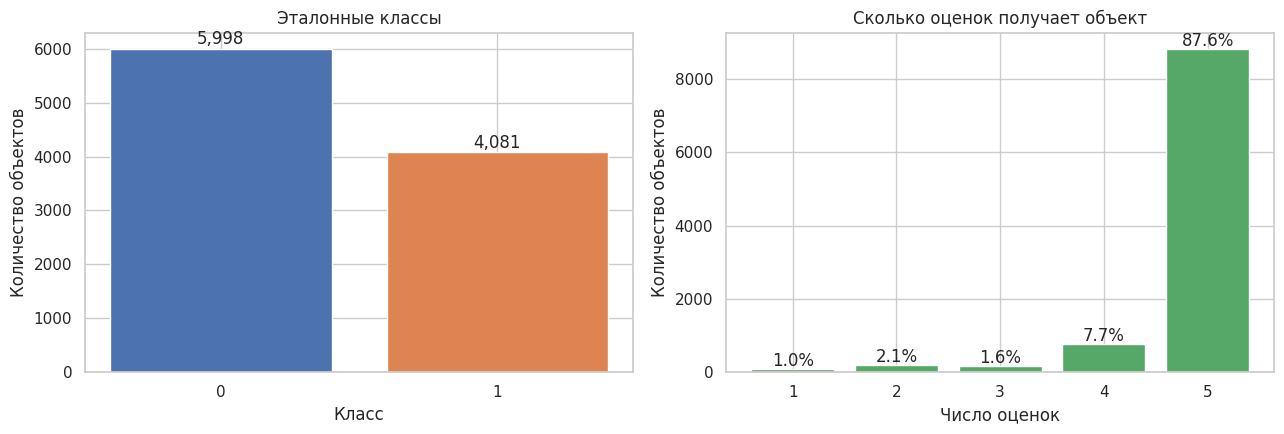

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].bar(class_counts.index, class_counts.values,
            color=["#4c72b0", "#dd8452"])
axes[0].set_title("Эталонные классы")
axes[0].set_xlabel("Класс")
axes[0].set_ylabel("Количество объектов")
for index, value in enumerate(class_counts.values):
    axes[0].text(index, value + 80, f"{value:,}", ha="center")

rating_counts = ratings_per_task.value_counts().sort_index()
axes[1].bar(rating_counts.index.astype(str), rating_counts.values,
            color="#55a868")
axes[1].set_title("Сколько оценок получает объект")
axes[1].set_xlabel("Число оценок")
axes[1].set_ylabel("Количество объектов")
for index, value in enumerate(rating_counts.values):
    axes[1].text(index, value + 80,
                 f"{value / len(ratings_per_task):.1%}", ha="center")

plt.tight_layout()
plt.show()

Оценок на объект почти всегда пять: судя по распределению, задания выдавались пачками по пять человек. Но встречаются объекты с одной, двумя, тремя и четырьмя оценками — например, когда часть ответов отфильтровали или задание остановили раньше. Из-за этого простые методы вроде голосования должны уметь обрабатывать и ничьи.

Классы распределены примерно 60/40 — заметный, но не экстремальный дисбаланс. Он важен для метрик: accuracy будет немного «оптимистичной», поэтому затем буду смотреть ещё и macro-F1.

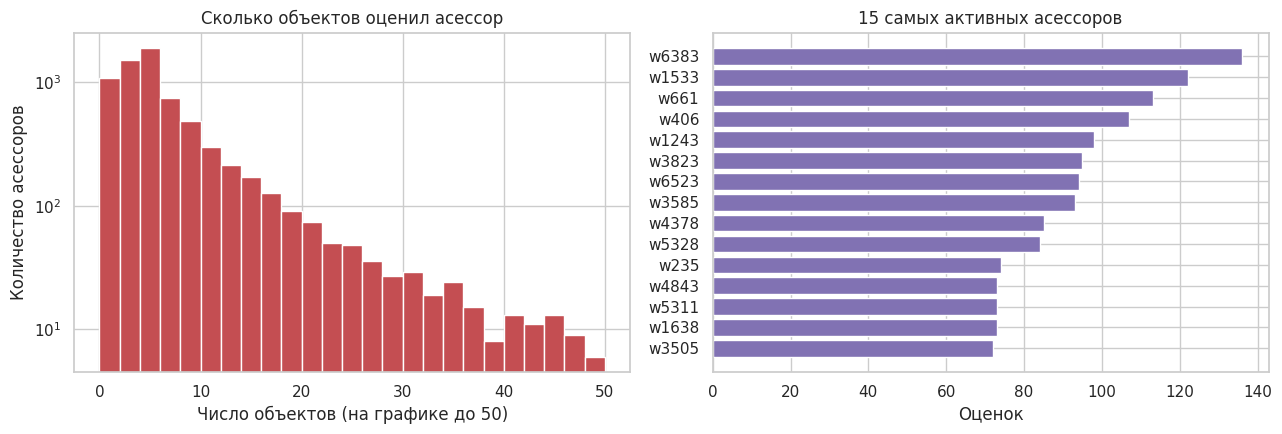

Доля асессоров с 1–5 оценками: 63.6%
Максимум оценок у одного асессора: 136


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].hist(tasks_per_worker, bins=np.arange(0, 52, 2),
             color="#c44e52", edgecolor="white")
axes[0].set_title("Сколько объектов оценил асессор")
axes[0].set_xlabel("Число объектов (на графике до 50)")
axes[0].set_ylabel("Количество асессоров")
axes[0].set_yscale("log")

top_workers = tasks_per_worker.sort_values(ascending=False).head(15)
axes[1].barh(top_workers.index[::-1], top_workers.values[::-1],
             color="#8172b3")
axes[1].set_title("15 самых активных асессоров")
axes[1].set_xlabel("Оценок")

plt.tight_layout()
plt.show()

print("Доля асессоров с 1–5 оценками:",
      f"{(tasks_per_worker <= 5).mean():.1%}")
print("Максимум оценок у одного асессора:", tasks_per_worker.max())

Активность асессоров распределена с длинным хвостом: больше половины сделали пять или меньше оценок, но есть люди с сотней и более. Такое распределение, опять же, типично для краудсорсинга — основную работу делают немногие опытные исполнители, а большинство заходит на несколько заданий.

## 4. Согласованность и надёжность

Чтобы понять, насколько асессоры вообще согласны друг с другом, считаю попарную согласованность внутри каждого объекта: для оценок $n_0$ и $n_1$ вероятность, что два случайно выбранных асессора совпадут, равна

$$\frac{n_0(n_0-1) + n_1(n_1-1)}{n(n-1)}.$$

Для сравнения привожу «случайный» уровень $p_0^2 + p_1^2$: столько совпадений было бы, если бы каждый асессор независимо бросал монетку с классовыми вероятностями. Если реальная согласованность заметно выше этого уровня, асессоры действительно оценивают объект, а не отвечают наугад.

Отдельно считаю точность каждого асессора на калибровочной части — именно она станет весом в Weighted Majority Vote.

In [9]:
def pairwise_agreement(labels: pd.Series) -> float:
    """Share of coinciding pairs among the ratings of one task."""
    counts = labels.value_counts()
    total = len(labels)
    if total < 2:
        return np.nan
    same_pairs = (counts * (counts - 1)).sum()
    return same_pairs / (total * (total - 1))


agreement_by_task = (
    annotations.groupby("task")["label"]
    .apply(pairwise_agreement)
    .dropna()
)

class_prior = calibration_truth.value_counts(normalize=True)
chance_agreement = (class_prior ** 2).sum()

print("Объектов с двумя и более оценками:", f"{len(agreement_by_task):,}")
print(f"Средняя согласованность: {agreement_by_task.mean():.4f}")
print(f"Медианная согласованность: {agreement_by_task.median():.4f}")
print(f"Случайный уровень: {chance_agreement:.4f}")
display(agreement_by_task.quantile(
    [0, 0.25, 0.5, 0.75, 1]
).to_frame("Согласованность"))

Объектов с двумя и более оценками: 9,983
Средняя согласованность: 0.6517
Медианная согласованность: 0.6000
Случайный уровень: 0.5181


,Согласованность
0.00,0.0
0.25,0.4
0.50,0.6
0.75,1.0
1.00,1.0


In [10]:
annotations_with_truth = calibration_annotations.merge(
    calibration_truth.rename("true_label"),
    left_on="task",
    right_index=True,
    how="inner",
)
annotations_with_truth["correct"] = (
    annotations_with_truth["label"] == annotations_with_truth["true_label"]
)

worker_stats = annotations_with_truth.groupby("worker").agg(
    answers=("correct", "size"),
    accuracy=("correct", "mean"),
)

print("Асессоров в калибровочной части:", f"{len(worker_stats):,}")
print(f"Средняя точность: {worker_stats['accuracy'].mean():.4f}")
print(f"Медианная точность: {worker_stats['accuracy'].median():.4f}")
display(worker_stats["accuracy"].quantile(
    [0, 0.25, 0.5, 0.75, 1]
).to_frame("Точность"))

Асессоров в калибровочной части: 5,217
Средняя точность: 0.6365
Медианная точность: 0.7500


,Точность
0.00,0.000000
0.25,0.333333
0.50,0.750000
0.75,1.000000
1.00,1.000000


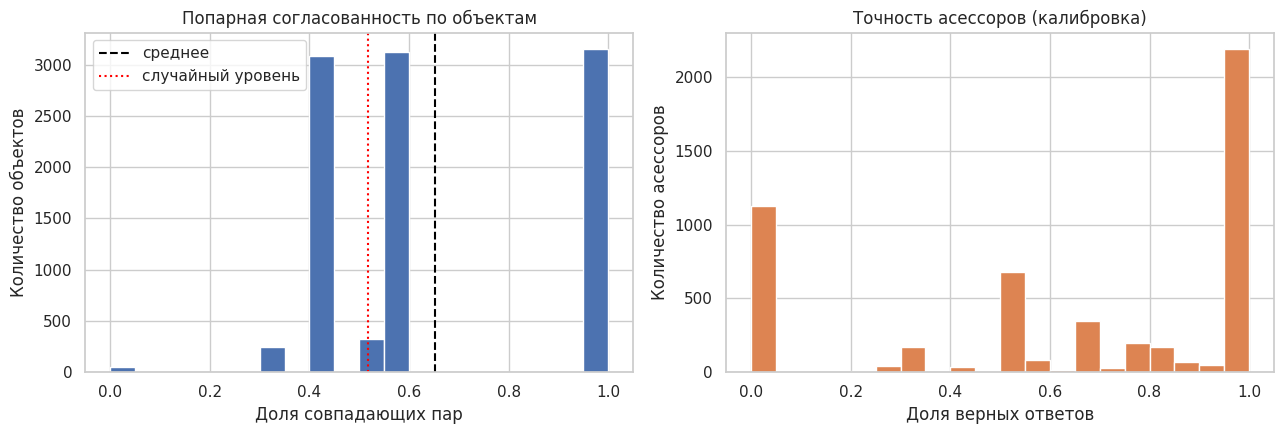

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].hist(agreement_by_task, bins=20, color="#4c72b0", edgecolor="white")
axes[0].axvline(agreement_by_task.mean(), color="black",
                linestyle="--", label="среднее")
axes[0].axvline(chance_agreement, color="red",
                linestyle=":", label="случайный уровень")
axes[0].set_title("Попарная согласованность по объектам")
axes[0].set_xlabel("Доля совпадающих пар")
axes[0].set_ylabel("Количество объектов")
axes[0].legend()

axes[1].hist(worker_stats["accuracy"], bins=20,
             color="#dd8452", edgecolor="white")
axes[1].set_title("Точность асессоров (калибровка)")
axes[1].set_xlabel("Доля верных ответов")
axes[1].set_ylabel("Количество асессоров")

plt.tight_layout()
plt.show()

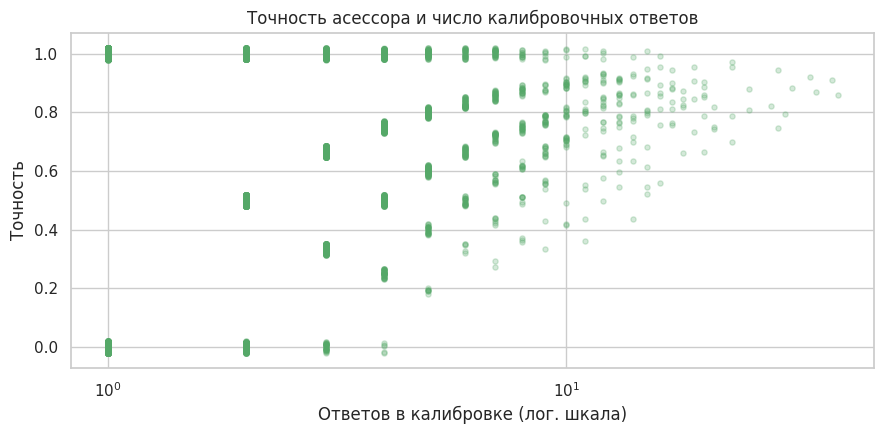

In [12]:
fig, ax = plt.subplots(figsize=(9, 4.5))

jitter = np.random.uniform(-0.02, 0.02, len(worker_stats))
ax.scatter(
    worker_stats["answers"],
    worker_stats["accuracy"] + jitter,
    alpha=0.25,
    s=14,
    color="#55a868",
)
ax.set_xscale("log")
ax.set_title("Точность асессора и число калибровочных ответов")
ax.set_xlabel("Ответов в калибровке (лог. шкала)")
ax.set_ylabel("Точность")
plt.tight_layout()
plt.show()

Согласованность в среднем 0,65 при случайном уровне 0,52. То есть асессоры видят задачу одинаково чаще, чем при случайном угадывании, но и расходятся довольно часто — объект, где все пять человек ответили одинаково, не редкость, но и не правило.

Точность отдельного асессора разбросана сильнее: медиана 0,75, но нижний квартиль — около 0,33. На графике «точность — число ответов» видно две вещи:
1. У людей с одним-двумя калибровочными ответами точность почти всегда либо 0, либо 1: одна ошибка — и 0,0, одно попадание — и 1,0.
2. У опытных асессоров точки собираются в районе 0,8–1,0.

Поэтому во взвешенном голосовании имеет смысл доверять индивидуальной точности только тем, у кого набралось достаточно ответов, а остальным давать общий средний вес.

## 5. Majority Vote

Самый простой метод: у каждого объекта берётся класс, за который отдано больше голосов. Никаких предположений о качестве асессоров — все считаются равными. Это понятный бейзлайн, с которым дальше сравниваю взвешенное голосование и Dawid–Skene.

Отдельно нужно правило для ничьих. Они возникают из-за неполных пачек: если у объекта чётное число оценок, голоса могут разделиться ровно пополам, а при одной-двух оценках и полном несовпадении ничья почти неизбежна. В таких случаях выбираю более частый класс по калибровочной истинной разметке — это нейтральное правило, не подглядывающее в тест. В коде это делает `choose_winner`: сначала находит максимальный счёт, а если среди лидеров есть априорный класс, отдаёт предпочтение ему.

Ещё вывожу структуру голосов на тесте — сколько объектов с полным согласием, сколько с большинством и сколько с ничьей. По ней видно, насколько агрегация вообще может что-то исправить: если бы все асессоры были согласны, все методы давали бы один и тот же ответ.

Класс для разрешения ничьих: 0
Доля объектов с ничьей: 2.14%
Предсказаний: 7056


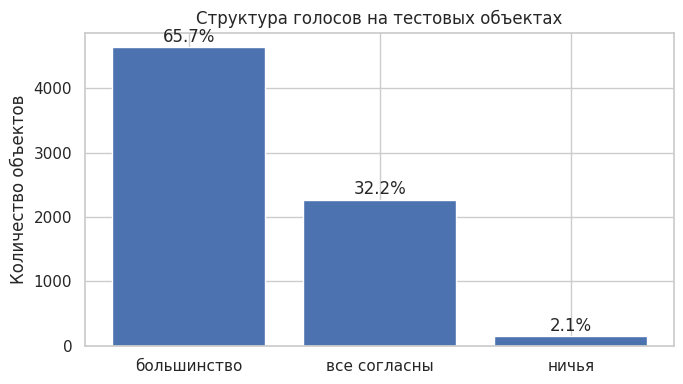

In [13]:
tie_break_label = class_prior.index[0]


def choose_winner(scores: pd.Series, tie_label: str) -> str:
    """Label with the highest score; ties go to the prior class."""
    best_score = scores.max()
    leaders = sorted(scores[scores == best_score].index)
    if tie_label in leaders:
        return tie_label
    return leaders[0]


def majority_vote(data: pd.DataFrame, tie_label: str) -> pd.Series:
    predictions = {}
    for task, group in data.groupby("task"):
        score = group["label"].value_counts()
        predictions[task] = choose_winner(score, tie_label)
    return pd.Series(predictions, name="prediction")


def vote_structure(labels: pd.Series) -> str:
    """How the votes of one task are split."""
    counts = labels.value_counts()
    if len(counts) == 1:
        return "все согласны"
    if counts.iloc[0] == counts.iloc[1]:
        return "ничья"
    return "большинство"


majority_predictions = majority_vote(test_annotations, tie_break_label)

structure = test_annotations.groupby("task")["label"].apply(vote_structure)
print("Класс для разрешения ничьих:", tie_break_label)
print("Доля объектов с ничьей:", f"{(structure == 'ничья').mean():.2%}")
print("Предсказаний:", len(majority_predictions))

plt.figure(figsize=(7, 4))
structure_counts = structure.value_counts()
structure_shares = structure.value_counts(normalize=True)
plt.bar(structure_counts.index, structure_counts.values, color="#4c72b0")
for position, (count, share) in enumerate(
    zip(structure_counts.values, structure_shares.values)
):
    plt.text(
        position,
        count + 80,
        f"{share:.1%}",
        ha="center",
    )
plt.title("Структура голосов на тестовых объектах")
plt.xlabel("")
plt.ylabel("Количество объектов")
plt.tight_layout()
plt.show()

## 6. Weighted Majority Vote

Идея — дать асессорам разные веса по их точности. Вес считаю только на калибровочной части, тест в этом не участвует.

Есть нюанс: у человека с двумя ответами точность 0, 0,5 или 1 — слишком шумная оценка. Поэтому ввожу порог: индивидуальная точность используется, только если у асессора не меньше 5 калибровочных ответов. Остальным присваивается средняя точность по «опытной» группе.

Из тестовых оценок около 86% принадлежат асессорам, которые вообще встречались в калибровке, а индивидуальный вес получают только 37% оценок. Поэтому неудивительно, что взвешенное голосование будет менять результаты голосования не так часто.

In [14]:
MIN_CALIBRATION_ANSWERS = 5

reliable_workers = worker_stats[
    worker_stats["answers"] >= MIN_CALIBRATION_ANSWERS
]
fallback_weight = reliable_workers["accuracy"].mean()

worker_weights = worker_stats["accuracy"].copy()
worker_weights.loc[
    worker_stats["answers"] < MIN_CALIBRATION_ANSWERS
] = fallback_weight

print("Асессоров с индивидуальным весом:", len(reliable_workers))
print("Всего асессоров в калибровке:", len(worker_stats))
print(f"Средний вес для остальных: {fallback_weight:.4f}")

test_worker_share = (
    test_annotations["worker"].isin(worker_weights.index).mean()
)
individual_share = (
    test_annotations["worker"].isin(reliable_workers.index).mean()
)
print(
    "Доля тестовых оценок от асессоров из калибровки: "
    f"{test_worker_share:.2%}"
)
print(
    "Доля тестовых оценок с индивидуальным весом: "
    f"{individual_share:.2%}"
)

Асессоров с индивидуальным весом: 782
Всего асессоров в калибровке: 5217
Средний вес для остальных: 0.7704
Доля тестовых оценок от асессоров из калибровки: 86.31%
Доля тестовых оценок с индивидуальным весом: 36.65%


In [15]:
def weighted_majority_vote(
    data: pd.DataFrame,
    weights: pd.Series,
    fallback_weight: float,
    tie_label: str,
) -> pd.Series:
    predictions = {}
    for task, group in data.groupby("task"):
        group = group.copy()
        group["weight"] = (
            group["worker"].map(weights).fillna(fallback_weight)
        )
        score = group.groupby("label")["weight"].sum()
        predictions[task] = choose_winner(score, tie_label)
    return pd.Series(predictions, name="prediction")


weighted_predictions = weighted_majority_vote(
    test_annotations,
    worker_weights,
    fallback_weight,
    tie_break_label,
)
print("Предсказаний:", len(weighted_predictions))

Предсказаний: 7056


## 7. Dawid–Skene

Dawid–Skene не нуждается в эталонных метках. Модель предполагает, что у каждого асессора есть своя матрица ошибок $P(\text{ответ} = k | \text{истинная метка} = j)$, и методом EM итеративно уточняет две вещи:

1. вероятности истинных меток для каждого объекта по текущим матрицам ошибок асессоров;
2. матрицы ошибок асессоров по текущим ожидаемым меткам объектов.

В отличие от взвешенного голосования, модель различает типы ошибок: асессор может быть хорош в распознавании релевантных документов и плох в распознавании нерелевантных — одна скалярная точность этого не передаёт.

Использую готовую реализацию из `crowd-kit` со 100 итерациями. Обучение идёт на тестовых аннотациях, потому что метод работает без эталона; эталон нужен только для финальной проверки.

In [16]:
dawid_skene_model = DawidSkene(n_iter=100)
dawid_skene_predictions = dawid_skene_model.fit_predict(
    test_annotations[["task", "worker", "label"]]
)
dawid_skene_predictions = (
    dawid_skene_predictions
    .reindex(test_truth.index)
    .dropna()
    .astype(str)
)

print("Предсказаний:", len(dawid_skene_predictions))
display(dawid_skene_predictions.head())

Предсказаний: 7056


,agg_label
task,
t88812,1
t64664,0
t5489,0
t97911,0
t90830,1


## 8. Сравнение методов

Качество проверяю на тестовой части по accuracy, macro-precision, macro-recall и macro-F1. Предсказания выравниваю по индексу объектов — так сравнение идёт на одинаковом наборе заданий.

In [17]:
def align_predictions(
    true_labels: pd.Series,
    predictions: pd.Series,
) -> Tuple[pd.Series, pd.Series]:
    """Keep the tasks both series have and cast the labels to strings."""
    predictions = predictions.reindex(true_labels.index).dropna().astype(str)
    true_labels = true_labels.loc[predictions.index].astype(str)
    return true_labels, predictions


def evaluate_predictions(
    true_labels: pd.Series,
    predictions: pd.Series,
    method_name: str,
) -> Dict[str, Any]:
    true_labels, predictions = align_predictions(true_labels, predictions)

    return {
        "Метод": method_name,
        "Объектов": len(predictions),
        "Accuracy": accuracy_score(true_labels, predictions),
        "Precision": precision_score(
            true_labels, predictions, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            true_labels, predictions, average="macro", zero_division=0
        ),
        "F1": f1_score(
            true_labels, predictions, average="macro", zero_division=0
        ),
    }


results = pd.DataFrame([
    evaluate_predictions(test_truth, majority_predictions, "Majority Vote"),
    evaluate_predictions(
        test_truth, weighted_predictions, "Weighted Majority Vote"
    ),
    evaluate_predictions(test_truth, dawid_skene_predictions, "Dawid–Skene"),
]).set_index("Метод")

display(results.round(4))

,Объектов,Accuracy,Precision,Recall,F1
Метод,,,,,
Majority Vote,7056,0.7803,0.7892,0.7983,0.7796
Weighted Majority Vote,7056,0.7791,0.7895,0.7981,0.7785
Dawid–Skene,7056,0.7949,0.7949,0.8059,0.7930


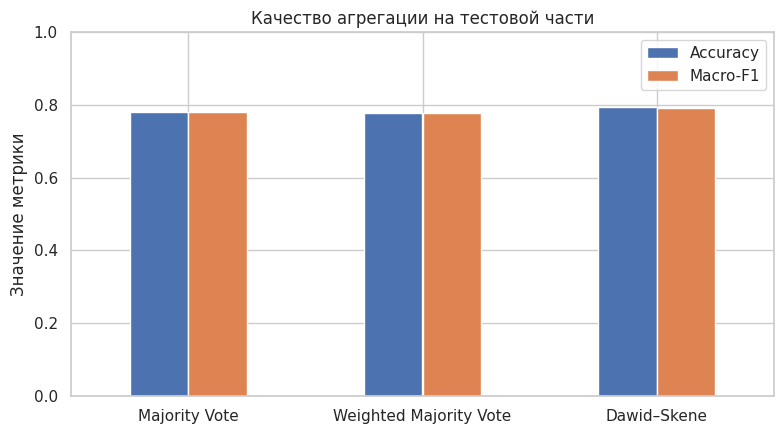

In [18]:
plot_data = results[["Accuracy", "F1"]].copy()

ax = plot_data.plot(
    kind="bar",
    figsize=(8, 4.5),
    ylim=(0, 1),
    color=["#4c72b0", "#dd8452"],
    rot=0,
)
ax.set_title("Качество агрегации на тестовой части")
ax.set_xlabel("")
ax.set_ylabel("Значение метрики")
ax.legend(["Accuracy", "Macro-F1"])
plt.tight_layout()
plt.show()

Все три метода дают близкий результат: accuracy около 0,78, macro-F1 — около 0,78–0,79. Dawid–Skene выигрывает примерно 0,014 по macro-F1 у Majority Vote, взвешенное голосование — нет.

Мне кажется, что это ожидаемо для данного датасета, потому что:

- индивидуальный вес есть только у 37% тестовых оценок; у остальных вес общий, одинаковый для всех;
- индивидуальная точность шумная, и её ошибки усредняются с ошибками ответов — при малом числе ответов на объект такой вес вредит не меньше, чем помогает;
- Dawid–Skene работает иначе: он оценивает не «надёжность асессора» в целом, а его склонность путать конкретные классы, и делает это одновременно с уточнением меток.

Сравниваю, насколько методы вообще меняют решения друг друга.

In [19]:
common_index = (
    majority_predictions.index
    .intersection(weighted_predictions.index)
    .intersection(dawid_skene_predictions.dropna().index)
)

mv = majority_predictions.loc[common_index]
wmv = weighted_predictions.loc[common_index]
ds = dawid_skene_predictions.loc[common_index]

print("Всего объектов:", len(common_index))
print("MV и WMV расходятся:",
      f"{(mv != wmv).sum()} ({(mv != wmv).mean():.2%})")
print("MV и Dawid–Skene расходятся:",
      f"{(mv != ds).sum()} ({(mv != ds).mean():.2%})")

Всего объектов: 7056
MV и WMV расходятся: 49 (0.69%)
MV и Dawid–Skene расходятся: 865 (12.26%)


Взвешенное голосование меняет меньше 1% решений — по сути, оно работает как обычное голосование. Dawid–Skene меняет около 12% предсказаний, то есть реально смотрит на структуру ошибок, а не просто повторяет большинство.

## 9. Ошибки по классам

Агрегация с одинаковой точностью по классам — редкость: если документов одного класса в разметке больше, методам проще на нём не ошибаться. Смотрю precision, recall и F1 отдельно по классам, а также матрицы ошибок.

In [20]:
def per_class_table(
    true_labels: pd.Series,
    predictions: pd.Series,
    method_name: str,
) -> pd.DataFrame:
    true_labels, predictions = align_predictions(true_labels, predictions)

    precision, recall, f1, support = precision_recall_fscore_support(
        true_labels,
        predictions,
        labels=["0", "1"],
        zero_division=0,
    )
    return pd.DataFrame({
        "Метод": method_name,
        "Класс": ["0 — нерелевантен", "1 — релевантен"],
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "Объектов": support,
    })


per_class = pd.concat([
    per_class_table(test_truth, majority_predictions, "Majority Vote"),
    per_class_table(test_truth, weighted_predictions,
                    "Weighted Majority Vote"),
    per_class_table(test_truth, dawid_skene_predictions, "Dawid–Skene"),
], ignore_index=True)

display(per_class.round(3))


,Метод,Класс,Precision,Recall,F1,Объектов
0,Majority Vote,0 — нерелевантен,0.906,0.704,0.792,4199
1,Majority Vote,1 — релевантен,0.672,0.893,0.767,2857
2,Weighted Majority Vote,0 — нерелевантен,0.910,0.698,0.790,4199
3,Weighted Majority Vote,1 — релевантен,0.669,0.898,0.767,2857
4,Dawid–Skene,0 — нерелевантен,0.890,0.748,0.813,4199
5,Dawid–Skene,1 — релевантен,0.700,0.864,0.773,2857


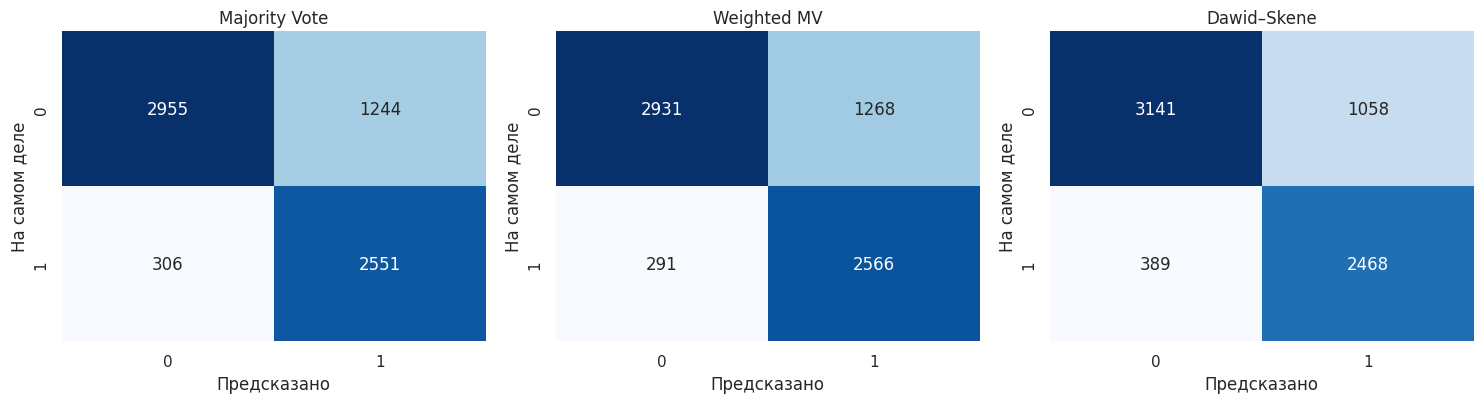

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
methods = [
    ("Majority Vote", majority_predictions),
    ("Weighted MV", weighted_predictions),
    ("Dawid–Skene", dawid_skene_predictions),
]

for ax, (name, predictions) in zip(axes, methods):
    true_labels, predictions = align_predictions(test_truth, predictions)

    matrix = confusion_matrix(true_labels, predictions, labels=["0", "1"])
    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["0", "1"],
        yticklabels=["0", "1"],
        ax=ax,
    )
    ax.set_title(name)
    ax.set_xlabel("Предсказано")
    ax.set_ylabel("На самом деле")

plt.tight_layout()
plt.show()


Картина у всех методов одинаковая по структуре. Значительно лучше распознаётся нерелевантный класс 0: у Majority Vote precision 0,9, recall 0,7. Релевантный класс 1, наоборот, ловится хорошо (recall 0,89), но с большим числом ложных срабатываний (precision 0,67). То есть методы предсказывают «1» охотнее, чем нужно: асессоры, похоже, склонны переоценивать релевантность документов.

Dawid–Skene слегка меняет этот баланс: recall класса 0 поднимается с 0,7 до 0,74, recall класса 1 падает с 0,89 до 0,86. За счёт этого F1 по обоим классам становится ближе друг к другу (0,81 и 0,77), а среднее значение растёт. Формально модель не знает, в какую сторону перекос: матрицы ошибок асессоров просто дают другой баланс предсказаний, чем правило большинства.

Weighted Majority Vote почти не отличается от обычного голосования: матрица ошибок меняется на десятки объектов из семи тысяч. Это честный отрицательный результат, и он объясняется как раз структурой данных.
## 10. Выводы

1. **Структура данных соответствует характерным особенностям краудсорсинговой разметки.** Наблюдаются неоднородная активность асессоров, неполное количество оценок для отдельных объектов, умеренный дисбаланс классов и различия в точности исполнителей. Эти особенности делают датасет подходящим для исследования методов агрегации.

2. **Простое большинство голосов — сильный baseline.** На тесте accuracy 0,78, macro-F1 0,77. Для бинарной задачи с пятью оценками на объект этого достаточно, чтобы отсечь случайные ошибки отдельных асессоров.

3. **Weighted Majority Vote не помог.** 0,77 по accuracy и 0,77 по macro-F1 — в пределах шума от Majority Vote. Причина в покрытии: индивидуальные веса есть только у 37% тестовых оценок, а там, где веса есть, индивидуальная точность оценена по небольшому числу ответов и сама содержит много шума.

4. **Dawid–Skene дал лучший результат.** accuracy 0,79, macro-F1 0,79. Прирост относительно Majority Vote небольшой: метод меняет около 12% предсказаний и немного выравнивает recall между классами. Утверждать статистическую значимость такого прироста по одному разбиению нельзя — для этого нужны повторные запуски на разных сплитах.

5. **Цена моделирования ошибок — интерпретируемость.** Majority Vote объясняется в одну фразу, Weighted MV — почти так же. Dawid–Skene требует EM, а его матрицы ошибок для асессоров с двумя-тремя ответами плохо определены. Когда разрыв в качестве невелик, выбор между методами — это выбор между простотой и небольшим выигрышем в F1.

6. **Ограничения.** Тестовая часть — 7 056 объектов, а разница между методами — 0,01–0,015; на таком объёме она небольшая, и при другом разбиении порядок методов может поменяться. Кроме того, калибровочная точность считается по всем типам документов сразу, без учёта запроса или тематики: асессор может быть силён в одной области и слаб в другой, и один скалярный вес этого не передаёт. Именно эту проблему и решает, я думаю, переход от взвешивания к вероятностным моделям.